# 🌊 Projekt: Klasifikace mořských živočichů — Milestone 2

**Advanced Architecture, Optimization & Defense**

V Milestone 1 jsme postavili datovou pipeline a natrénovali konvoluční sítě **od nuly**. Nejlepší z nich
(vylepšená CNN) dosáhla **56,6 % accuracy na testu**. Teď chceme výkon výrazně zvednout pomocí
**transfer learningu**, moderní regularizace a pokročilých postupů tréninku — a u každé úpravy
**změřit, kolik přinesla**.

### Plán notebooku
| Část | Obsah | Požadavek zadání |
|---|---|---|
| 0 — Navázání na M1 | výsledky z Milestone 1 (E0) | — |
| 1 — Data | stejný split, transformace pro předtrénovanou síť, CutMix / Mixup | 2. augmentace |
| 2 — Model | předtrénovaná ResNet-50, bloky a parametry | 1. architektura (varianta A) |
| 3 — E1: jen hlava | zmrazená síť, trénuje se jen nová poslední vrstva | 1. zmrazení |
| 4 — E2: fine-tuning | postupné odmrazování, různé learning rate, warmup + cosine | 1. + 3. |
| 5 — E3: regularizace | + CutMix / Mixup, Random Erasing, label smoothing | 2. |
| 6 — Srovnání experimentů | tabulka a křivky | 3. sledování experimentů |
| 7 — Analýza chyb | confusion matrix, nejhorší vzorky | 5. |
| 8 — Test a shrnutí | jednorázové vyhodnocení, závěry | 6. |

### Struktura repozitáře
Společný kód je v modulech, notebook ho importuje a obsahuje vysvětlení, experimenty a interpretaci:

| Soubor | Obsah |
|---|---|
| `src/data.py` | split, `SeaAnimalsDataset`, transformace, DataLoadery |
| `src/models.py` | ResNet-50, zmrazování / odmrazování bloků, skupiny parametrů |
| `src/train.py` | CutMix / Mixup, plánovač lr, tréninková smyčka, `fit()` s logy |
| `runs/<experiment>/` | `config.json` (nastavení), `log.csv` (metriky po epochách), `best.pt` (váhy, mimo git) |

> 💡 **Reprodukovatelnost:** každý experiment je popsaný jedním slovníkem `config`, který se uloží do
> `runs/<jméno>/config.json`. Když experiment s touto konfigurací už proběhl, notebook ho **netrénuje znovu**
> a jen načte uložené logy a váhy. Přetrénovat jde nastavením `RETRAIN = True`.

## ⚙️ Nastavení prostředí

Notebook běží lokálně v prostředí `.venv` (GTX 1080, PyTorch 2.14 + CUDA 12.6). Seznam knihoven je
v `requirements.txt`.

- `set_seed` nastaví pevný seed a **deterministické cuDNN** — stejně jako v M1, aby šly výsledky zopakovat.
- **Mixed precision (AMP) nepoužíváme:** GTX 1080 (architektura Pascal) nemá tensor cores a ve float16
  počítá výrazně pomaleji než ve float32 — trénink by se zpomalil, ne zrychlil.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from src.data import IMAGENET_MEAN, IMAGENET_STD, SeaAnimalsDataset, build_transforms, make_splits
from src.models import BLOCKS, block_params, build_resnet50, count_params, set_trainable
from src.train import fit, mix_batch, set_seed

sns.set_theme(style="whitegrid")

SEED = 42
RETRAIN = False                     # True = přetrénovat i experimenty, které už jsou v runs/
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch: 2.14.0+cu126 | device: cuda | NVIDIA GeForce GTX 1080


# 📌 Část 0 — Navázání na Milestone 1 (E0)

Výchozí bod jsou dva modely z Milestone 1 (notebook `ML_GEM0023_milestone_01.ipynb`), oba trénované **od nuly**
na obrázcích 128 × 128:

| Model (M1) | Parametrů | Val accuracy | Test accuracy | Test macro accuracy |
|---|---|---|---|---|
| Baseline CNN (3 vrstvy) | 0,40 mil. | 41,1 % | 39,5 % | 35,9 % |
| Vylepšená CNN (4 bloky, BatchNorm, GAP, augmentace) | 1,18 mil. | 55,1 % | 56,6 % | 54,1 % |

Hlavní poznatky z M1, na které navazujeme:
- Síť od nuly se na ~9,5 tisíci trénovacích obrázků **snadno přeučí** — pomohla až silná regularizace.
- Nejtěžší jsou **vizuálně podobné třídy** (Fish / Puffers, Squid / Octopus, Eel).
- Přesnost je limitovaná **množstvím dat** — síť se musí naučit rozpoznávat hrany, textury i tvary jen
  z našich obrázků. Přesně tohle řeší transfer learning.

Čísla si uložíme do slovníku `results`, kam budeme přidávat i všechny experimenty z M2.

In [2]:
results = {
    "E0a baseline CNN (M1)":  {"val_acc": 0.411, "test_acc": 0.395},
    "E0b vylepšená CNN (M1)": {"val_acc": 0.551, "test_acc": 0.566},
}
pd.DataFrame(results).T

,val_acc,test_acc
E0a baseline CNN (M1),0.411,0.395
E0b vylepšená CNN (M1),0.551,0.566


# 📦 Část 1 — Data

## ✂️ Stejný split jako v Milestone 1

Aby bylo srovnání s M1 férové, musí modely vidět **přesně stejná** trénovací, validační a testovací data.
Funkce `make_splits` zopakuje stratifikovaný split 70 / 15 / 15 se stejným seedem a uloží ho do
`splits/{train,val,test}.csv`. Split je tak **pevně uložený v repozitáři** — nezávisí na tom, jestli se
někdy změní pořadí řádků nebo verze knihovny.

In [3]:
splits = make_splits("sea_animals_index.csv", "splits", seed=SEED)
for name, df in splits.items():
    print(f"{name:<5} {len(df):5d} obrázků")

idx_to_class = dict(zip(splits["train"]["label_idx"], splits["train"]["label"]))
idx_to_class = dict(sorted(idx_to_class.items()))
N_CLASSES = len(idx_to_class)
print("Tříd:", N_CLASSES)

train  9515 obrázků
val    2039 obrázků
test   2040 obrázků
Tříd: 23


## 🔄 Transformace pro předtrénovanou síť

Předtrénovaná síť očekává vstup **připravený stejně jako při jejím původním tréninku** (cvičení 4:
`weights.transforms()`). Proto se oproti M1 mění dvě věci:

| | Milestone 1 | Milestone 2 | Proč |
|---|---|---|---|
| Rozlišení | 128 × 128 | **224 × 224** | na této velikosti byla ResNet-50 trénovaná |
| Normalizace | vlastní mean/std (R 0,32 · G 0,41 · B 0,42) | **ImageNet** (0,485 · 0,456 · 0,406) | naučené filtry „čekají“ vstupy v rozsahu, ve kterém je viděly na ImageNetu |
| Validace / test | `Resize` na čtverec | `Resize(232)` + `CenterCrop(224)` | přesně preprocessing vah `IMAGENET1K_V2` — zachová poměr stran, ořízne okraje |

> 💡 **Proč nepoužít naše vlastní mean/std:** první konvoluce ResNet-50 se naučila filtry pro data
> normalizovaná statistikami ImageNetu. Kdybychom normalizovali jinak, všechny vstupy by byly „posunuté“
> (např. podvodní fotky by po naší normalizaci měly víc červené, než síť zná) a předtrénované filtry by
> fungovaly hůř. Tohle je jedna z nejčastějších chyb v transfer learningu.

Trénovací augmentace je stejná jako u vylepšeného modelu v M1 (náhodný výřez, flip, mírná změna barev).
Silnější augmentace (Random Erasing, CutMix, Mixup) přidáme až v experimentu E3, abychom změřili jejich přínos.

train: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.6, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

eval: Compose(
    Resize(size=232, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

batch: (8, 3, 224, 224) torch.float32 | labely: (8,) torch.int64


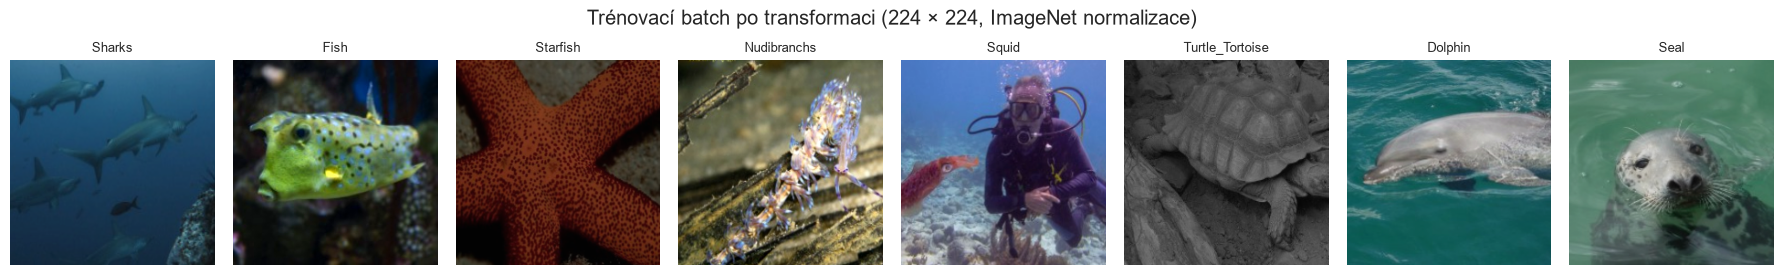

In [4]:
train_tf, eval_tf = build_transforms(img_size=224)
print("train:", train_tf)
print("\neval:", eval_tf)

def denormalize(x):
    # (3, H, W) normalizovaný tenzor -> obrázek 0–1 pro matplotlib
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1).permute(1, 2, 0)

# jeden batch pro ukázku (num_workers=0 — kvůli 8 obrázkům nemá smysl spouštět workery)
demo_loader = DataLoader(SeaAnimalsDataset(splits["train"], train_tf), batch_size=8, shuffle=True,
                         generator=torch.Generator().manual_seed(SEED))
x_demo, y_demo = next(iter(demo_loader))
print("\nbatch:", tuple(x_demo.shape), x_demo.dtype, "| labely:", tuple(y_demo.shape), y_demo.dtype)

fig, axes = plt.subplots(1, 8, figsize=(18, 2.8))
for ax, img, lbl in zip(axes, x_demo, y_demo):
    ax.imshow(denormalize(img)); ax.set_title(idx_to_class[lbl.item()], fontsize=9); ax.axis("off")
fig.suptitle("Trénovací batch po transformaci (224 × 224, ImageNet normalizace)")
plt.tight_layout(); plt.show()

## 🎨 CutMix a Mixup — ukázka

Dvě **dynamické augmentace**, které použijeme v E3. Na rozdíl od flipu nebo výřezu nemění jen obrázek,
ale **míchají dva obrázky a jejich labely**:

| Metoda | Obrázek | Label |
|---|---|---|
| **Mixup** | průhledné prolnutí: `lam · A + (1 − lam) · B` | `lam` dílu třídy A + `(1 − lam)` dílu třídy B |
| **CutMix** | do obrázku A se vloží obdélník z obrázku B | podle plochy: kolik % obrázku zůstalo z A |

`lam` se pro každý batch losuje z Beta rozdělení. Loss se pak počítá smíchaně:
`lam · CE(predikce, třída A) + (1 − lam) · CE(predikce, třída B)`.

**Proč to pomáhá:**
- **CutMix** nutí síť rozpoznat zvíře i z **části** těla — nemůže se spoléhat na jeden výrazný detail
  (třeba oko), protože ten může být překrytý.
- **Mixup** učí síť **neodpovídat přehnaně sebejistě** — správná odpověď je „70 % želva, 30 % tuleň“,
  ne „100 % želva“. To je přesně problém, který jsme viděli v M1 (rostoucí val loss = příliš sebejisté chyby).
- Obojí vytváří nekonečně mnoho nových kombinací ⇒ silná regularizace proti přeučení.

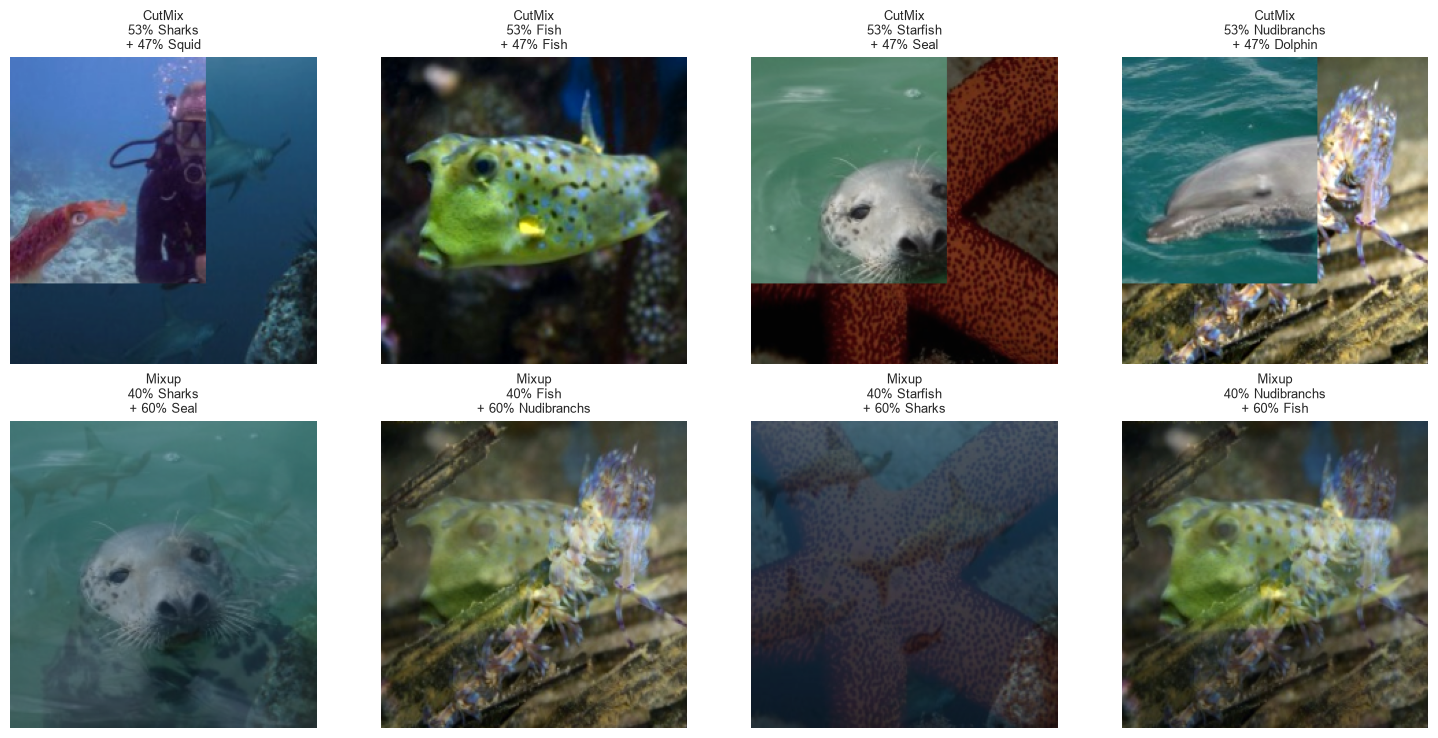

In [5]:
def mix_for_demo(**kwargs):
    # Pro ukázku losujeme znovu, dokud lam nevyjde mezi 0,3 a 0,7 — jinak by smíchání nebylo vidět.
    # Při tréninku se lam NEvybírá: Beta(alpha, alpha) s alpha < 1 má tvar „U“ a často dává lam blízko
    # 0 nebo 1 (obrázek skoro beze změny) — jen občas vznikne výrazně smíchaný obrázek.
    while True:
        out = mix_batch(x_demo, y_demo, **kwargs)
        if 0.3 <= out[3] <= 0.7:
            return out

torch.manual_seed(SEED)
x_cm, ya_cm, yb_cm, lam_cm = mix_for_demo(cutmix_alpha=1.0)
x_mu, ya_mu, yb_mu, lam_mu = mix_for_demo(mixup_alpha=0.4)

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for row, (xm, ya, yb, lam, name) in enumerate([(x_cm, ya_cm, yb_cm, lam_cm, "CutMix"),
                                                 (x_mu, ya_mu, yb_mu, lam_mu, "Mixup")]):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(denormalize(xm[col])); ax.axis("off")
        ax.set_title(f"{name}\n{lam:.0%} {idx_to_class[ya[col].item()]}\n"
                     f"+ {1 - lam:.0%} {idx_to_class[yb[col].item()]}", fontsize=9)
plt.tight_layout(); plt.show()

# 🧠 Část 2 — Model: předtrénovaná ResNet-50

Stejně jako ve cvičení 4 použijeme **ResNet-50** z `torchvision` s vahami natrénovanými na **ImageNetu**
(1,28 milionu obrázků, 1 000 tříd; váhy `IMAGENET1K_V2`: 80,9 % top-1 accuracy na ImageNetu).

**Proč ResNet-50:**
- dobře známá architektura ze cvičení — umíme vysvětlit každý krok,
- ImageNet obsahuje i mořská zvířata (žraloky, želvy, medúzy, ryby…) ⇒ naučené vzory jsou pro nás velmi relevantní,
- velikost odpovídá naší GPU: plný fine-tuning se vejde do 8 GB paměti (batch 32, ~6,3 GB).

**Residual connections:** ResNet je postavená z bloků, kde se vstup bloku **přičte k jeho výstupu**
(`výstup = F(x) + x`). Gradient tak může téct „zkratkou“ přímo k nižším vrstvám a jde trénovat i velmi
hluboké sítě (50 vrstev) — bez toho by gradient při průchodu desítkami vrstev slábl.

**Úprava pro naši úlohu:** původní hlava `model.fc` = `Linear(2048 → 1000 tříd ImageNetu)` nahradíme
vlastní `Dropout(0,2) → Linear(2048 → 23)`. Dropout přidáváme jako regularizaci — nová hlava má jen
~47 tisíc vah, ale 23 tříd a málo dat.

Síť si rozdělíme na **bloky**, které budeme postupně odmrazovat. Čím dál od vstupu, tím specifičtější
vzory blok rozpoznává:

| Blok | Co rozpoznává | Výstup (pro vstup 224 × 224) |
|---|---|---|
| `stem` (conv1 + bn1) | hrany, barvy | 64 × 112 × 112 (pak MaxPool → 56 × 56) |
| `layer1` | jednoduché textury | 256 × 56 × 56 |
| `layer2` | složitější textury, vzory | 512 × 28 × 28 |
| `layer3` | části objektů (ploutev, oko, krunýř) | 1024 × 14 × 14 |
| `layer4` | celé objekty, nejvíc specifické pro ImageNet | 2048 × 7 × 7 |
| `fc` (naše hlava) | 23 tříd | 23 |

In [6]:
model = build_resnet50(N_CLASSES).to(device)
print("Nová hlava:", model.fc)

total, _ = count_params(model)
print(f"\n{'blok':<8} {'parametrů':>12} {'podíl':>7}")
for name in BLOCKS:
    n = sum(p.numel() for p in block_params(model, name))
    print(f"{name:<8} {n:>12,} {n / total:>7.1%}")
print(f"{'celkem':<8} {total:>12,}")

# Kolik parametrů se trénuje při různém odmrazení (= kolik práce má optimizer)
print()
for blocks in [[], ["layer4"], ["layer3", "layer4"], ["stem", "layer1", "layer2", "layer3", "layer4"]]:
    set_trainable(model, blocks)
    print(f"odmrazeno {str(blocks or 'jen hlava'):<52} -> trénovatelných {count_params(model)[1]:>11,}")

# Kontrola tvarů: batch z Části 1 -> 23 logitů
model.eval()
with torch.no_grad():
    out = model(x_demo.to(device))
print("\nvstup", tuple(x_demo.shape), "-> výstup", tuple(out.shape))
assert out.shape == (x_demo.shape[0], N_CLASSES)
del model; torch.cuda.empty_cache()

Nová hlava: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=2048, out_features=23, bias=True)
)

blok        parametrů   podíl
stem            9,536    0.0%
layer1        215,808    0.9%
layer2      1,219,584    5.2%
layer3      7,098,368   30.1%
layer4     14,964,736   63.5%
fc             47,127    0.2%
celkem     23,555,159

odmrazeno jen hlava                                            -> trénovatelných      47,127
odmrazeno ['layer4']                                           -> trénovatelných  15,011,863
odmrazeno ['layer3', 'layer4']                                 -> trénovatelných  22,110,231
odmrazeno ['stem', 'layer1', 'layer2', 'layer3', 'layer4']     -> trénovatelných  23,555,159

vstup (8, 3, 224, 224) -> výstup (8, 23)


> 💡 **Kde jsou parametry:** `layer4` obsahuje **64 %** všech vah sítě, `layer3` dalších 30 %. Odmrazení
> `layer4` tedy znamená skok z 47 tisíc na 15 milionů trénovatelných parametrů — proto se odmrazuje
> opatrně, postupně a s malým learning rate.

# 🧊 Část 3 — Experiment E1: zmrazená síť, trénuje se jen hlava

První krok transfer learningu (cvičení 4: *feature extraction phase*): **celou předtrénovanou síť zmrazíme**
a trénujeme jen novou hlavu. ResNet-50 tak slouží jako hotový „extraktor vlastností“ — z každého obrázku
spočítá 2 048 čísel a hlava se z nich učí rozhodnout o třídě.

**Co tím měříme:** kolik přinese **samotné předtrénování** bez jakéhokoli přizpůsobení sítě našim datům.

| Nastavení | Hodnota | Proč |
|---|---|---|
| odmrazené bloky | žádné (jen hlava, 47 tisíc parametrů) | čistý efekt předtrénovaných vlastností |
| BatchNorm | statistiky zmrazené (`freeze_bn_stats`) | zachováme statistiky z ImageNetu (`bn_frozen` ze cvičení) |
| optimizer | AdamW, lr = 1e-3, weight decay 0,01 | hlava je nová (náhodné váhy) ⇒ může se učit rychle |
| plánovač lr | 1 epocha warmup + cosine | viz Část 4; tady hlavně pro konzistenci s dalšími experimenty |
| epochy | 8 | hlava je malá, učí se rychle |
| augmentace | jako vylepšený model v M1 (výřez, flip, barvy) | bez CutMix / Mixup — ty přidáme v E3 |
| batch | 32 | stejný ve všech experimentech (plný fine-tuning se větší nevejde do paměti) |

In [7]:
CONFIG_E1 = {
    "name": "E1_head_only",
    "seed": SEED, "img_size": 224, "batch_size": 32, "num_workers": 4,
    "epochs": 8, "warmup_epochs": 1,
    "unfreeze_schedule": {"1": []},           # celou dobu jen hlava
    "lrs": {"fc": 1e-3},
    "weight_decay": 0.01, "dropout": 0.2,
    "label_smoothing": 0.0, "mixup_alpha": 0.0, "cutmix_alpha": 0.0, "mix_prob": 0.0,
    "random_erasing": 0.0,
}

model_e1, log_e1 = fit(CONFIG_E1, splits, N_CLASSES, device, retrain=RETRAIN)
results["E1 jen hlava"] = {"val_acc": log_e1["val_acc"].max()}
log_e1

[E1_head_only] načteno z runs\E1_head_only (nejlepší val acc 85.9%)


,epoch,blocks,lr_head,train_loss,train_acc,val_loss,val_acc,seconds
0,1,-,0.000003,2.287842,0.512664,1.285960,0.796469,76.7
1,2,-,0.001000,0.916846,0.826484,0.716311,0.835704,26.0
2,3,-,0.000950,0.633139,0.852549,0.593290,0.847474,28.2
3,4,-,0.000812,0.546139,0.865160,0.543491,0.851398,26.7
4,5,-,0.000611,0.503900,0.868839,0.520077,0.854340,26.6
5,6,-,0.000389,0.483982,0.874514,0.509651,0.858754,26.1
6,7,-,0.000188,0.460328,0.885339,0.505159,0.859245,26.0
7,8,-,0.000050,0.459047,0.880820,0.504624,0.858264,25.8


### 📈 Křivky učení

Funkci pro kreslení křivek budeme používat u všech experimentů. Kreslí loss, accuracy a learning rate hlavy
po epochách; svislé čáry označují epochy, kdy se odmrazil další blok.

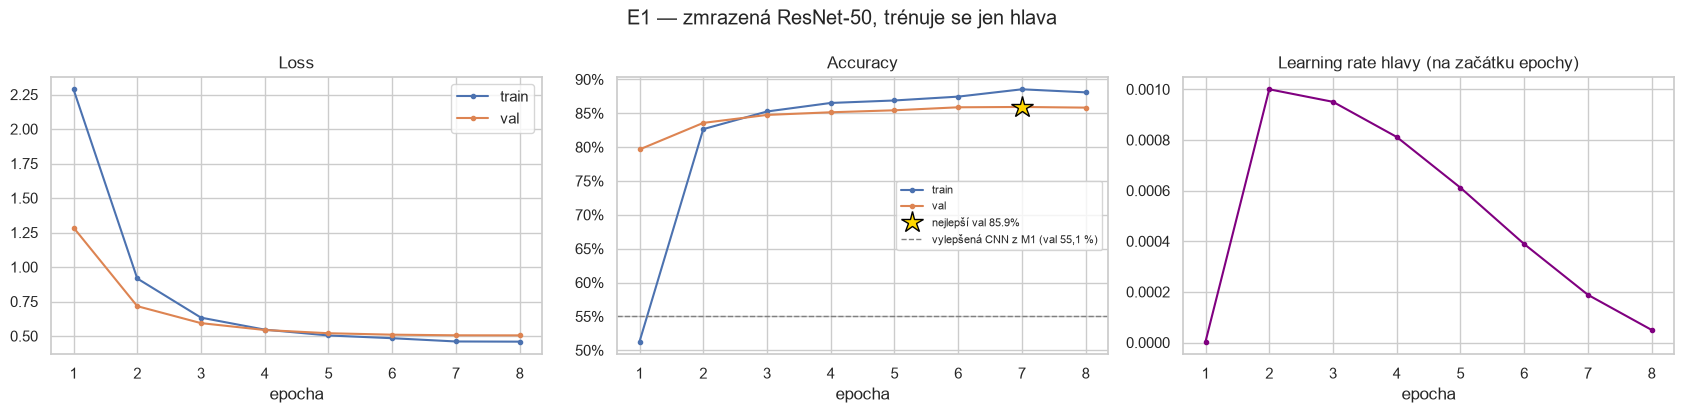

In [8]:
def plot_log(log, title):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
    ep = log["epoch"]
    axes[0].plot(ep, log["train_loss"], "o-", ms=3, label="train")
    axes[0].plot(ep, log["val_loss"], "o-", ms=3, label="val")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epocha"); axes[0].legend()

    axes[1].plot(ep, log["train_acc"], "o-", ms=3, label="train")
    axes[1].plot(ep, log["val_acc"], "o-", ms=3, label="val")
    best = log["val_acc"].idxmax()
    axes[1].plot(log.loc[best, "epoch"], log.loc[best, "val_acc"], "*", color="gold", ms=16,
                 markeredgecolor="black", label=f"nejlepší val {log.loc[best, 'val_acc']:.1%}")
    axes[1].axhline(0.551, color="gray", ls="--", lw=1, label="vylepšená CNN z M1 (val 55,1 %)")
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("epocha"); axes[1].legend(fontsize=8)

    axes[2].plot(ep, log["lr_head"], "o-", ms=3, color="purple")
    axes[2].set_title("Learning rate hlavy (na začátku epochy)"); axes[2].set_xlabel("epocha")

    for i in range(1, len(log)):                          # změna odmrazených bloků
        if log["blocks"].iloc[i] != log["blocks"].iloc[i - 1]:
            for ax in axes:
                ax.axvline(log["epoch"].iloc[i] - 0.5, color="red", ls=":", lw=1)
            prev = set(log["blocks"].iloc[i - 1].split("+"))
            added = [b for b in log["blocks"].iloc[i].split("+") if b not in prev]
            text = "+ zbytek sítě" if len(added) > 1 else "+ " + added[0]
            axes[1].text(log["epoch"].iloc[i] - 0.4, axes[1].get_ylim()[0] + 0.02, text,
                         color="red", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()


plot_log(log_e1, "E1 — zmrazená ResNet-50, trénuje se jen hlava")

### 📝 Interpretace E1

- **Obrovský skok:** nejlepší val accuracy **85,9 %** (7. epocha) proti **55,1 %** u nejlepší sítě z M1
  (+30,8 p. b.) — a to se trénovala jen nová hlava se **47 tisíci** parametry (síť z M1 jich měla 1,18 milionu).
  Vlastnosti, které se ResNet-50 naučila na ImageNetu (hrany, textury, tvary, části zvířat), se tedy na
  podvodní fotky **přenášejí velmi dobře**. Přesně to je smysl transfer learningu.
- **Už po první epoše 79,6 %** — hlava se jen učí, jak z hotových 2 048 vlastností poskládat 23 tříd.
- **Val accuracy je v 1. epoše vyšší než train** (79,6 % vs. 51,3 %): train accuracy je průměr přes celou
  epochu, během které se model teprve učil (a lr při warmupu stoupal z nuly). Validace se měří až na konci
  epochy. Navíc train data jsou augmentovaná a při tréninku je zapnutý Dropout.
- **Žádné přeučení:** train 88 % vs. val 86 %, val loss klesá až do konce (0,505). Hlava má málo parametrů
  a nemá si co „zapamatovat“.
- **Strop:** od ~5. epochy se val accuracy zastaví kolem 85–86 %. Vlastnosti z ResNet-50 jsou **pevné**
  (zmrazené) a naučené pro ImageNet — hlava z nich víc nevytěží. Další zlepšení vyžaduje **přizpůsobit
  samotné vlastnosti našim datům** ⇒ odmrazit část sítě (experiment E2).
- **Rychlost:** ~26 s na epochu (první epocha 77 s kvůli startu workerů), celkem 4,4 min.

# 🔥 Část 4 — Experiment E2: postupné odmrazování a různé learning rate

E1 narazil na strop ~86 %, protože vlastnosti sítě byly **pevné**. V E2 je necháme **přizpůsobit našim datům**
(*fine-tuning*). Dělat to ale musíme opatrně — předtrénované váhy jsou cenné a velké kroky optimizeru by je
mohly „rozbít“ (tzv. *catastrophic forgetting*).

## 🧊➜🔥 Postupné odmrazování (gradual unfreezing)

| Epochy | Odmrazeno | Trénovatelných parametrů | Proč |
|---|---|---|---|
| 1–3 | jen hlava | 47 tis. | hlava má na začátku **náhodné váhy** ⇒ její gradienty jsou velké a nesmyslné. Nejdřív ji „usadíme“ (jako E1), aby do sítě neposílala šum |
| 4–6 | + `layer4` | 15,0 mil. | nejvyšší blok má vlastnosti **nejvíc specifické pro ImageNet** ⇒ potřebuje přizpůsobit nejvíc |
| 7–9 | + `layer3` | 22,1 mil. | části objektů (ploutve, krunýře…) |
| 10–15 | celá síť | 23,6 mil. | nakonec jemně doladíme i obecné vrstvy |

Odmrazujeme **od konce sítě k začátku**: nižší vrstvy (hrany, textury) jsou obecné a fungují pro jakékoliv
fotky, takže je měníme nejméně a nejpozději.

## 🎚️ Různé learning rate pro různé bloky (discriminative learning rates)

Stejná myšlenka jako u odmrazování, ale pro velikost kroku — každý blok má vlastní **skupinu parametrů**
v optimizeru (cvičení 4: *parameter groups*):

| Blok | lr | Proč |
|---|---|---|
| `fc` (hlava) | 1e-3 | nová vrstva, učí se od nuly ⇒ velké kroky |
| `layer4` | 1e-4 | 10× méně — přizpůsobuje se, ale nesmí zapomenout, co umí |
| `layer3` | 3e-5 | |
| `layer2`, `layer1`, `stem` | 1e-5 | obecné vlastnosti — jen nepatrné doladění (lr ze cvičení 4 pro fine-tuning celé sítě) |

> 💡 Optimizer dostane **všechny skupiny hned od začátku**. Dokud je blok zmrazený, jeho parametry nemají
> gradient a optimizer je přeskočí. Po odmrazení se začnou učit se svým lr — nemusíme vytvářet nový
> optimizer a neztratí se jeho vnitřní stav (průměry gradientů v AdamW).

## 📉 Plánovač: warmup + cosine annealing

Násobitel learning rate (stejný pro všechny skupiny, takže poměry mezi bloky zůstávají):
- **warmup (1. epocha):** lineárně z ~0 na 1 — první kroky s náhodnou hlavou jsou opatrné,
- **cosine (zbytek):** plynulý pokles po křivce kosinu z 1 k 0 — na začátku velké kroky (rychlý pokrok),
  na konci malé (jemné doladění, model se „usadí“ v dobrém minimu).

Po kroku každého batche se lr přepočítá. Když se v 4. epoše odmrazí `layer4`, začne s lr = 1e-4 × aktuální
násobitel — díky tomu se nové bloky zapojují už s mírně sníženým lr.

## ⚙️ Ostatní nastavení
Stejné jako E1 (AdamW, weight decay 0,01, dropout 0,2, augmentace z M1, batch 32), **bez** CutMix / Mixup
a label smoothingu — ty přidá E3. Změna oproti E1 je tedy jen v odmrazování a learning rate ⇒ rozdíl
výsledků můžeme přičíst právě fine-tuningu.

In [9]:
ALL_BLOCKS = ["stem", "layer1", "layer2", "layer3", "layer4"]

CONFIG_E2 = {
    "name": "E2_gradual_unfreeze",
    "seed": SEED, "img_size": 224, "batch_size": 32, "num_workers": 4,
    "epochs": 15, "warmup_epochs": 1,
    "unfreeze_schedule": {
        "1": [],                           # epochy 1–3: jen hlava
        "4": ["layer4"],                   # 4–6
        "7": ["layer3", "layer4"],         # 7–9
        "10": ALL_BLOCKS,                  # 10–15: celá síť
    },
    "lrs": {"stem": 1e-5, "layer1": 1e-5, "layer2": 1e-5, "layer3": 3e-5, "layer4": 1e-4, "fc": 1e-3},
    "weight_decay": 0.01, "dropout": 0.2,
    "label_smoothing": 0.0, "mixup_alpha": 0.0, "cutmix_alpha": 0.0, "mix_prob": 0.0,
    "random_erasing": 0.0,
}

model_e2, log_e2 = fit(CONFIG_E2, splits, N_CLASSES, device, retrain=RETRAIN)
results["E2 postupné odmrazování"] = {"val_acc": log_e2["val_acc"].max()}
log_e2

[E2_gradual_unfreeze] načteno z runs\E2_gradual_unfreeze (nejlepší val acc 90.2%)


,epoch,blocks,lr_head,train_loss,train_acc,val_loss,val_acc,seconds
0,1,-,0.000003,2.287842,0.512664,1.285960,0.796469,72.0
1,2,-,0.001000,0.916070,0.826590,0.714003,0.836194,26.0
2,3,-,0.000987,0.628922,0.852759,0.586551,0.848455,26.0
3,4,layer4,0.000950,0.462412,0.864635,0.407192,0.883276,35.0
4,5,layer4,0.000891,0.240980,0.930215,0.392330,0.890633,35.1
5,6,layer4,0.000812,0.140293,0.959327,0.418559,0.887690,34.7
6,7,layer3+layer4,0.000717,0.172063,0.945560,0.431381,0.890633,49.8
7,8,layer3+layer4,0.000611,0.089512,0.973305,0.459098,0.886219,50.7
8,9,layer3+layer4,0.000500,0.060942,0.981503,0.453786,0.892104,49.7
9,10,stem+layer1+layer2+layer3+layer4,0.000389,0.099678,0.970573,0.461976,0.892594,87.9


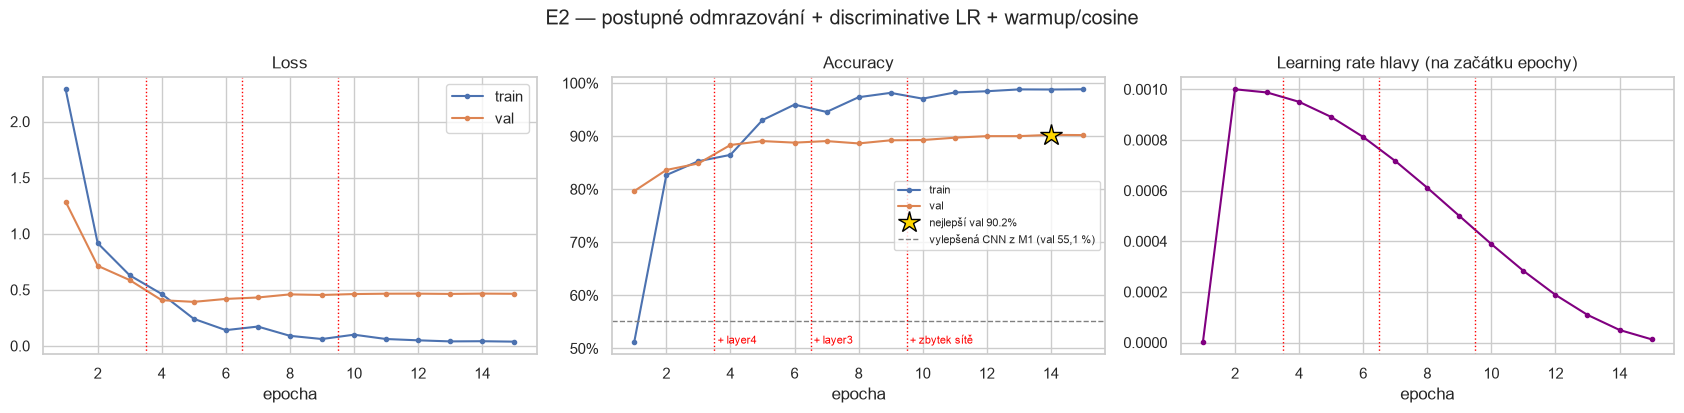

In [10]:
plot_log(log_e2, "E2 — postupné odmrazování + discriminative LR + warmup/cosine")

### 📝 Interpretace E2

- **Výsledek:** nejlepší val accuracy **90,2 %** (14. epocha) — o **+4,3 p. b.** víc než E1 (85,9 %).
  Přizpůsobení předtrénovaných vlastností našim datům tedy pomohlo.
- **Epochy 1–3 jsou téměř shodné s E1** (stejný seed, jen hlava) — to je kontrola, že rozdíl dál způsobuje
  opravdu odmrazování. Drobné rozdíly jsou jen v lr (kosinová křivka je v E2 roztažená na 15 epoch).
- **Kolik přinesl který krok:**

  | Krok | Val accuracy (konec fáze) | Přínos | Čas epochy |
  |---|---|---|---|
  | jen hlava (ep. 1–3) | 84,8 % | — | 26 s |
  | + `layer4` (ep. 4–6) | 88,8 % (max 89,1 %) | **+4,0 p. b.** — hned po odmrazení skok o 3,5 p. b. | 35 s |
  | + `layer3` (ep. 7–9) | 89,2 % | +0,4 p. b. | 50 s |
  | + zbytek sítě (ep. 10–15) | 90,2 % | +1,0 p. b. | 88 s |

  ⇒ **Nejvíc pomohl `layer4`** — obsahuje nejvíc parametrů (64 %) a vlastnosti nejvíc specifické pro
  ImageNet, které bylo potřeba přizpůsobit. Každý další blok přidá méně a stojí víc času
  (celá síť ~3,4× pomalejší než jen hlava) — přesně odpovídá tomu, že nižší vrstvy jsou obecné.
- **Objevilo se přeučení:**
  - train accuracy vystoupala na **98,8 %**, validační zůstala na ~90 % (rozdíl ~9 p. b.; v E1 jen 2 p. b.),
  - **val loss je nejnižší v 5. epoše (0,39)** a pak mírně **stoupá** (0,46), i když val accuracy ještě roste.
    Model tedy klasifikuje správně o něco víc obrázků, ale u chybných predikcí je **čím dál sebejistější** —
    stejný jev jako u baseline v M1, jen mnohem slabší.
  - Příčina: 23,6 milionu odmrazených parametrů na ~9,5 tisíce obrázků ⇒ síť si trénovací data postupně
    zapamatuje (train loss 0,04).
- **Warmup + cosine** funguje podle plánu: lr hlavy během 1. epochy vystoupá na 1e-3 a pak plynule klesá.
  Malý lr na konci (ep. 12–15) „usadí“ model — val accuracy se ustálí na ~90 %.

➡️ **Co z toho plyne pro E3:** síť má dost kapacity, problém je přeučení ⇒ přidáme **silnější regularizaci**
(CutMix / Mixup, Random Erasing, label smoothing), která by měla zmenšit rozdíl train vs. val a hlavně
**snížit sebejistotu u chyb** (val loss).

# 🛡️ Část 5 — Experiment E3: regularizace (CutMix / Mixup, Random Erasing, label smoothing)

E2 ukázal, že síť má **dost kapacity**, ale **přeučuje se** (train 98,8 % vs. val 90 %, val loss od 5. epochy
roste). E3 proto přidává **regularizaci** — techniky, které ztěžují zapamatování trénovacích dat.
**Všechno ostatní zůstává stejné jako v E2** (odmrazování, learning rate, plánovač, 15 epoch), takže rozdíl
výsledků lze přičíst právě regularizaci.

| Technika | Nastavení | Jak funguje | Co řeší |
|---|---|---|---|
| **CutMix** | α = 1,0 | do obrázku vloží obdélník z jiného obrázku, label se smíchá podle plochy | síť musí poznat zvíře i z **části** těla |
| **Mixup** | α = 0,2 | průhledně prolne dva obrázky, label ve stejném poměru | **méně sebejisté** predikce, plynulejší rozhodovací hranice mezi třídami |
| (kombinace) | míchá se **50 %** batchů, pokaždé náhodně jedna z metod | | polovina batchů zůstane čistá ⇒ síť se učí i na skutečných obrázcích |
| **Random Erasing** | p = 0,25 | v každém 4. obrázku vymaže náhodný obdélník (po normalizaci) | síť se nespoléhá na jedno konkrétní místo obrázku |
| **Label smoothing** | 0,1 | cíl pro správnou třídu je 0,9 místo 1,0, zbytek se rozdělí mezi ostatní třídy | model **není přehnaně sebejistý** — přímo míří na rostoucí val loss z E2 |

**Proč tyto hodnoty:** α = 1,0 pro CutMix (rovnoměrné losování velikosti výřezu) a α = 0,2 pro Mixup
(většinou jen slabé prolnutí) jsou běžná výchozí nastavení z původních článků. Label smoothing 0,1 a Random
Erasing p = 0,25 jsou také standardní výchozí hodnoty. Na malém datasetu je nechceme přehánět —
**příliš silná regularizace** by zpomalila učení natolik, že by 15 epoch nestačilo.

> 💡 **Train accuracy bude nižší než v E2** — smíchané a částečně vymazané obrázky jsou těžší a u smíchaných
> batchů se accuracy počítá vážená poměrem `lam`. To je u regularizace žádoucí. Důležitá je **validační**
> accuracy a loss (validační data se nemíchají a loss se počítá bez label smoothingu ⇒ je přímo srovnatelná s E1/E2).

In [11]:
CONFIG_E3 = {
    **CONFIG_E2,                               # vše stejné jako E2 ...
    "name": "E3_regularization",
    "label_smoothing": 0.1,                    # ... plus regularizace
    "mixup_alpha": 0.2, "cutmix_alpha": 1.0, "mix_prob": 0.5,
    "random_erasing": 0.25,
}

model_e3, log_e3 = fit(CONFIG_E3, splits, N_CLASSES, device, retrain=RETRAIN)
results["E3 + regularizace"] = {"val_acc": log_e3["val_acc"].max()}
log_e3

[E3_regularization] epocha 1: odmrazeno nic + hlava -> trénovatelných 47,127 parametrů


[E3_regularization] epocha  1/15 | train loss 2.528 acc  44.0% | val loss 1.457 acc  79.5% |  73.3 s ⭐


[E3_regularization] epocha  2/15 | train loss 1.590 acc  71.8% | val loss 0.868 acc  83.8% |  25.8 s ⭐


[E3_regularization] epocha  3/15 | train loss 1.437 acc  73.8% | val loss 0.738 acc  85.4% |  26.0 s ⭐


[E3_regularization] epocha 4: odmrazeno ['layer4'] + hlava -> trénovatelných 15,011,863 parametrů


[E3_regularization] epocha  4/15 | train loss 1.342 acc  76.0% | val loss 0.537 acc  88.1% |  35.8 s ⭐


... (11 outputs left out)

[E3_regularization] epocha 14/15 | train loss 1.005 acc  86.9% | val loss 0.483 acc  90.5% |  88.5 s


[E3_regularization] epocha 15/15 | train loss 1.056 acc  85.1% | val loss 0.440 acc  91.0% |  86.4 s ⭐


[E3_regularization] hotovo za 15.2 min, nejlepší val acc 91.0%


,epoch,blocks,lr_head,train_loss,train_acc,val_loss,val_acc,seconds
0,1,-,0.000003,2.528440,0.440499,1.457331,0.795488,73.3
1,2,-,0.001000,1.589558,0.717817,0.868299,0.837666,25.8
2,3,-,0.000987,1.437061,0.737942,0.737765,0.853850,26.0
3,4,layer4,0.000950,1.341572,0.760337,0.536560,0.880824,35.8
4,5,layer4,0.000891,1.197441,0.812107,0.458536,0.894066,35.8
5,6,layer4,0.000812,1.119967,0.840445,0.489573,0.889161,36.0
6,7,layer3+layer4,0.000717,1.104920,0.847945,0.495503,0.896518,50.7
7,8,layer3+layer4,0.000611,1.090536,0.849219,0.482152,0.901913,50.9
8,9,layer3+layer4,0.000500,1.016644,0.875131,0.446809,0.907308,50.2
9,10,stem+layer1+layer2+layer3+layer4,0.000389,1.098205,0.845506,0.472258,0.904365,88.1


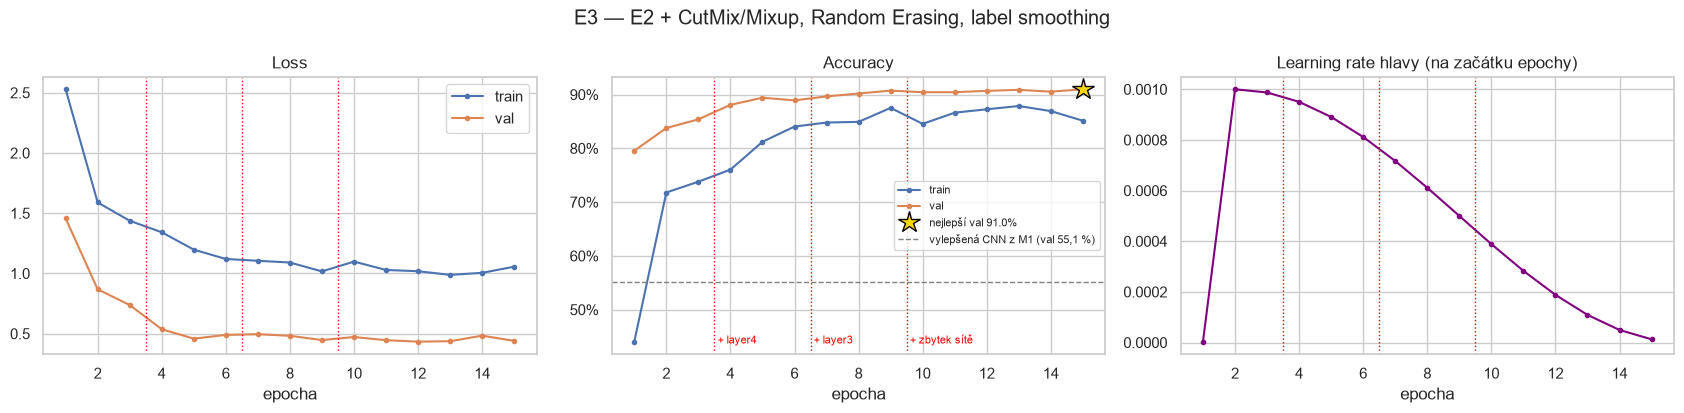

In [12]:
plot_log(log_e3, "E3 — E2 + CutMix/Mixup, Random Erasing, label smoothing")

### 📝 Interpretace E3

| | E2 (bez regularizace) | E3 (+ regularizace) |
|---|---|---|
| Nejlepší val accuracy | 90,2 % (ep. 14) | **91,0 %** (ep. 15) |
| Val loss — minimum | 0,39 (ep. 5) | 0,43 (ep. 12) |
| Val loss — na konci | 0,46 (**rostla** od 5. epochy) | **0,44** (bez růstu, kolísá 0,43–0,50) |
| Train accuracy na konci | 98,8 % | 85,1 % (smíchaná data — není přímo srovnatelná) |

- **Hlavní efekt: přeučení zmizelo.** V E2 val loss od 5. epochy rostla (model byl u chyb stále sebejistější).
  V E3 se po odmrazení `layer4` drží kolem 0,44–0,49 a **nestoupá** až do konce tréninku. Train loss zůstává
  vysoko (~1,0), protože smíchané a vymazané obrázky si síť zapamatovat nemůže.
- **Val accuracy +0,8 p. b.** (90,2 → 91,0 %). To je ~16 obrázků z 2 039 navíc správně. Rozdíl je **malý** a
  máme jen jeden běh se stejným seedem, takže část rozdílu může být náhoda — **nelze ho brát jako jednoznačné
  zlepšení přesnosti**. Jednoznačnější je zlepšení **chování** modelu (val loss).
- **Val loss není s E2 úplně srovnatelná:** model s label smoothingem se učí dávat správné třídě ~90 %, ne 100 %,
  takže i u správných predikcí má vyšší loss (−ln 0,9 ≈ 0,1 místo ~0). Že je přesto val loss na konci nižší
  než v E2, znamená, že výrazně klesla loss u **chybných** predikcí — model už není přehnaně sebejistý, když se mýlí.
- **Proč je train accuracy nižší než validační:** u smíchaných batchů se zásah počítá vážený poměrem `lam`
  (model nemůže „trefit“ 100 % obrázku, který je ze 60 % želva a ze 40 % tuleň) a Random Erasing občas zakryje
  podstatnou část zvířete. Validační obrázky jsou čisté.
- **Model se pořád mírně zlepšuje** — nejlepší epocha je ta poslední. Regularizovaný model se učí pomaleji,
  takže by mu pravděpodobně prospěl delší trénink.
- **Čas:** stejný jako E2 (15,2 min) — CutMix / Mixup / Random Erasing jsou výpočetně zanedbatelné.

➡️ **Závěr:** regularizace splnila hlavní cíl — **odstranila přeučení** a model je spolehlivější v tom, jak
moc si je jistý. Na přesnosti přidala jen málo, protože už E2 byl blízko stropu, který ResNet-50 na 224 px
a ~9,5 tisíci obrázků umožňuje.